In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
df = pd.read_excel("inflow_loading_obs.xlsx", engine="openpyxl")

# 按时间排序
df = df.sort_values("jday").reset_index(drop=True)

# 定义列
inflow_cols  = [f"inflow{i}" for i in range(1, 9)]
loading_cols = [f"loading{i}" for i in range(1, 9)]
obs_cols     = [f"obs{i}" for i in range(1, 13)]

# 查看缺失值
df[inflow_cols + loading_cols + obs_cols].isna().sum()


,0
inflow1,0
inflow2,0
inflow3,0
inflow4,0
inflow5,0
inflow6,0
inflow7,0
inflow8,0
loading1,0
loading2,0


In [ ]:
df = df.dropna(subset=inflow_cols + loading_cols + obs_cols)


In [ ]:
df.shape

(143625, 29)

/tmp/ipython-input-2935446472.py:10: UserWarning: Glyph 19982 (\N{CJK UNIFIED IDEOGRAPH-4E0E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2935446472.py:10: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2935446472.py:10: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2935446472.py:10: UserWarning: Glyph 20851 (\N{CJK UNIFIED IDEOGRAPH-5173}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2935446472.py:10: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 19982 (\N{CJK UNIFIED IDEOGRAPH-4E0E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPyt

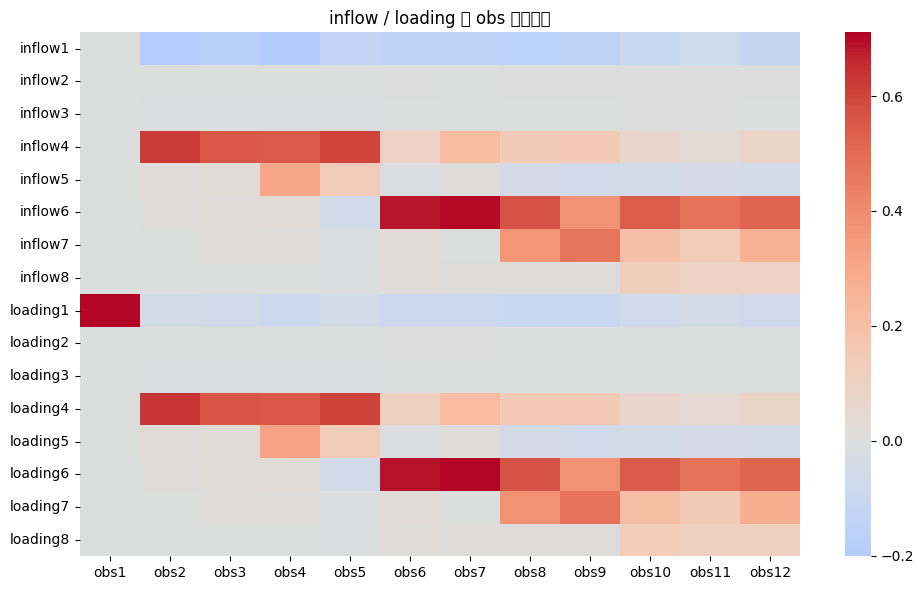

In [ ]:
corr = df[inflow_cols + loading_cols + obs_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    corr.loc[inflow_cols + loading_cols, obs_cols],
    cmap="coolwarm",
    center=0
)
plt.title("inflow / loading 与 obs 的相关性")
plt.tight_layout()
plt.show()


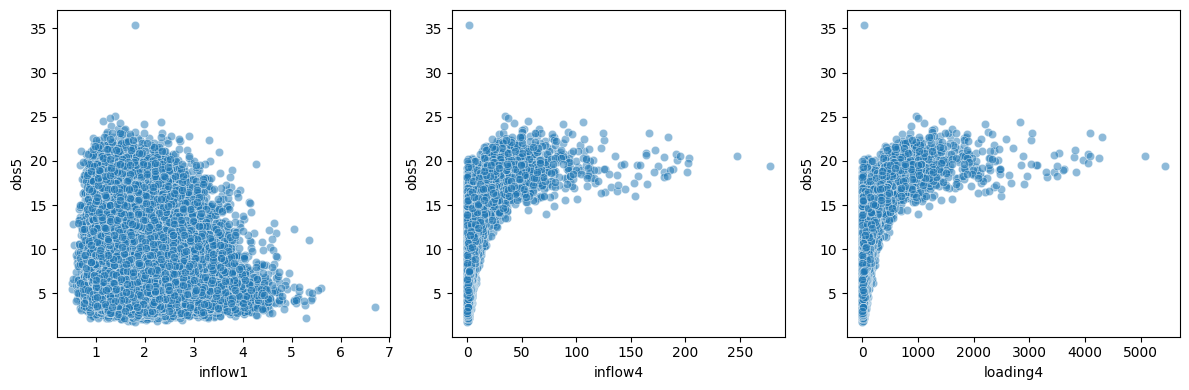

In [ ]:
sample_obs = "obs5"

plt.figure(figsize=(12, 4))

for i, col in enumerate(["inflow1", "inflow4", "loading4"]):
    plt.subplot(1, 3, i+1)
    sns.scatterplot(x=df[col], y=df[sample_obs], alpha=0.5)
    plt.xlabel(col)
    plt.ylabel(sample_obs)

plt.tight_layout()
plt.show()


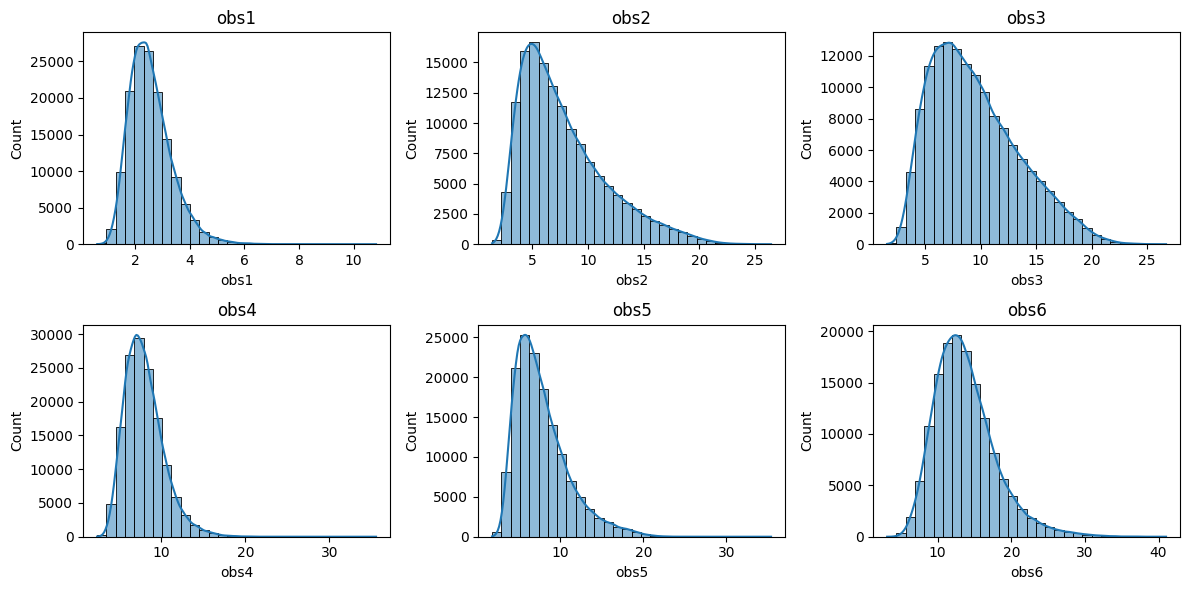

In [ ]:
plt.figure(figsize=(12, 6))
for i, col in enumerate(obs_cols[:6]):
    plt.subplot(2, 3, i+1)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()


In [ ]:
!pip install lightgbm

In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor

import lightgbm as lgb


# 1. EDA 后的 df

inflow_cols  = [f"inflow{i}" for i in range(1, 9)]
loading_cols = [f"loading{i}" for i in range(1, 9)]
obs_cols     = [f"obs{i}" for i in range(1, 13)]

X = df[inflow_cols + loading_cols]
Y = df[obs_cols]


# 2. 按时间顺序切分

n = len(df)
test_size = int(0.2 * n)

X_train, X_test = X.iloc[:-test_size], X.iloc[-test_size:]
Y_train, Y_test = Y.iloc[:-test_size], Y.iloc[-test_size:]


# 3. 评估函数（逐 obs + 平均）

def evaluate(y_true, y_pred, targets):
    rows = []
    for i, col in enumerate(targets):
        mae = mean_absolute_error(y_true[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i]))
        r2 = r2_score(y_true[:, i], y_pred[:, i])
        rows.append([col, mae, rmse, r2])

    df_eval = pd.DataFrame(rows, columns=["obs", "MAE", "RMSE", "R2"])
    df_eval.loc["AVG"] = [
        "AVG",
        df_eval["MAE"].mean(),
        df_eval["RMSE"].mean(),
        df_eval["R2"].mean()
    ]
    return df_eval



# 4. 模型配置

models = {
    #  线性基线
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MultiOutputRegressor(
            Ridge(alpha=1.0)
        ))
    ]),

    #  稀疏线性
    "ElasticNet": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MultiOutputRegressor(
            ElasticNet(
                alpha=0.1,
                l1_ratio=0.5,
                max_iter=5000,
                random_state=0
            )
        ))
    ]),

    #  Boosting（sklearn）
    "HistGradientBoosting": MultiOutputRegressor(
        HistGradientBoostingRegressor(
            max_depth=6,
            learning_rate=0.05,
            max_iter=300,
            random_state=0
        )
    ),

    #  Boosting（LightGBM）
    "LightGBM": MultiOutputRegressor(
        lgb.LGBMRegressor(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=0,
            n_jobs=-1
        )
    ),

    #  Bagging 随机树
    "ExtraTrees": MultiOutputRegressor(
        ExtraTreesRegressor(
            n_estimators=50,
            max_depth=6,
            min_samples_leaf=10,
            random_state=0,
            n_jobs=-1
        )
    )
}



# 5. 训练与评估

summary = []
predictions = {}
for name, model in models.items():
    print(f"\n===== Training {name} =====")

    t0 = time.time()
    model.fit(X_train, Y_train)
    fit_time = time.time() - t0

    t1 = time.time()
    y_pred = model.predict(X_test)
    pred_time = time.time() - t1

    predictions[name] = pd.DataFrame(
    y_pred,
    columns=obs_cols,
    index=Y_test.index
    )

    metrics = evaluate(
        Y_test.to_numpy(),
        np.asarray(y_pred),
        obs_cols
    )

    print(metrics)

    summary.append([
        name,
        fit_time,
        pred_time,
        metrics.loc["AVG", "RMSE"],
        metrics.loc["AVG", "R2"]
    ])



# 6. 总体模型对比

summary_df = pd.DataFrame(
    summary,
    columns=["Model", "TrainTime(s)", "PredTime(s)", "AVG_RMSE", "AVG_R2"]
)

print("\n===== Model Comparison =====")
print(summary_df.sort_values("AVG_RMSE"))



===== Training Ridge =====
       obs       MAE      RMSE        R2
0     obs1  0.135324  0.215593  0.922929
1     obs2  2.200737  2.819794  0.460484
2     obs3  2.523596  3.151556  0.362092
3     obs4  1.257450  1.692335  0.460506
4     obs5  1.876580  2.437219  0.417854
5     obs6  2.129448  2.821707  0.541881
6     obs7  2.034641  2.639981  0.592070
7     obs8  1.907356  2.474919  0.532739
8     obs9  1.893219  2.454478  0.432253
9    obs10  1.765255  2.310814  0.395057
10   obs11  1.923246  2.529994  0.293164
11   obs12  1.825377  2.358963  0.398596
AVG    AVG  1.789352  2.325613  0.484135

===== Training ElasticNet =====
       obs       MAE      RMSE        R2
0     obs1  0.208808  0.291045  0.859543
1     obs2  2.242501  2.855723  0.446648
2     obs3  2.561358  3.184742  0.348586
3     obs4  1.294072  1.716474  0.445005
4     obs5  1.907235  2.459777  0.407028
5     obs6  2.178196  2.850551  0.532467
6     obs7  2.083434  2.668158  0.583316
7     obs8  1.958674  2.514769  0.517

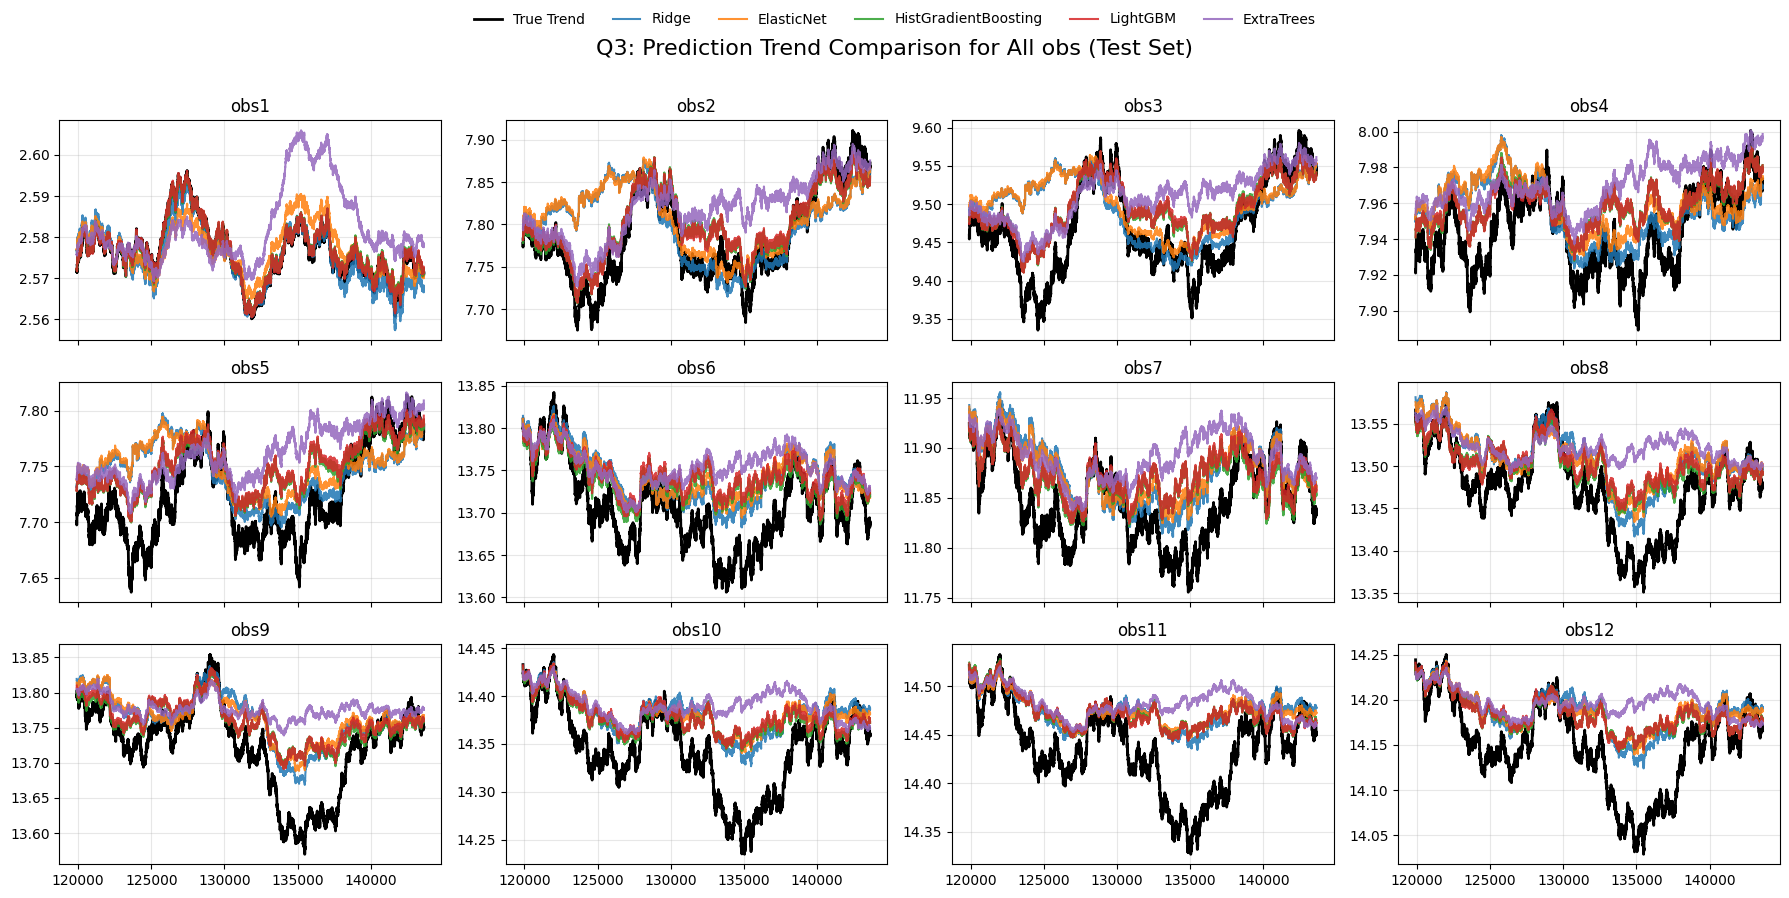

In [ ]:
SAimport matplotlib.pyplot as plt


#参数设置

window = 5000
models_to_plot = list(predictions.keys())

n_obs = len(obs_cols)
n_cols = 4
n_rows = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 9), sharex=True)
axes = axes.flatten()


#逐 obs 画趋势图

for i, obs in enumerate(obs_cols):
    ax = axes[i]

    #真实趋势
    true_trend = Y_test[obs].rolling(window).mean()
    ax.plot(
        true_trend.index,
        true_trend,
        color="black",
        linewidth=2,
        label="True Trend" if i == 0 else None
    )

    #各模型预测趋势
    for name in models_to_plot:
        pred_trend = predictions[name][obs].rolling(window).mean()
        ax.plot(
            pred_trend.index,
            pred_trend,
            linewidth=1.5,
            alpha=0.85,
            label=name if i == 0 else None
        )

    ax.set_title(obs)
    ax.grid(alpha=0.3)


# 全局图例 + 标题

fig.suptitle(
    "Q3: Prediction Trend Comparison for All obs (Test Set)",
    fontsize=16,
    y=0.96
)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=6,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


In [ ]:
import numpy as np
import pandas as pd
import shap

from sklearn.ensemble import HistGradientBoostingRegressor


# 1. 定义输入与输出变量（与 Q3 保持一致）


# inflow 和 loading 各 8 个点位
inflow_cols  = [f"inflow{i}" for i in range(1, 9)]
loading_cols = [f"loading{i}" for i in range(1, 9)]

# 所有输入特征
X_cols = inflow_cols + loading_cols

# obs 输出变量
obs_cols = [f"obs{i}" for i in range(1, 13)]

# 特征矩阵
X = df[X_cols]



# 2. 单个 obs 的“高值原因识别”函数

def identify_cause_one_obs(
    obs_col,
    quantile=0.95,
    max_events=20,
    background_size=50
):
    """
    对单个 obs 变量进行高值原因分析：

    参数说明：
    - obs_col: 当前分析的 obs 名称（如 'obs5'）
    - quantile: 定义“相对高值”的分位数（默认 P95）
    - max_events: 最多分析多少个高值样本（防止计算过慢）
    - background_size: SHAP 使用的背景样本数量（用于加速）

    返回：
    - threshold: 高值阈值
    - freq: 各 inflow+loading 点位组成为主因的频率
    """

    # 取当前 obs 作为预测目标
    y = df[obs_col].values


    #1 训练梯度提升树模型

    model = HistGradientBoostingRegressor(
        max_depth=6,
        learning_rate=0.05,
        max_iter=300,
        random_state=0
    )
    model.fit(X, y)


    #2 定义“相对高值”（分位数）

    threshold = np.quantile(y, quantile)

    # 找出高于阈值的样本索引，并限制数量
    high_idx = np.where(y >= threshold)[0][:max_events]

    if len(high_idx) == 0:
        return None


    #3 使用 SHAP 进行解释（小背景集）

    background = X.sample(
        n=min(background_size, len(X)),
        random_state=0
    )

    explainer = shap.Explainer(model, background)
    shap_values = explainer(X.iloc[high_idx],check_additivity=False)


    #4 将 SHAP 值按点位分组
    # inflow_k + loading_k 视为同一采集点

    group_contrib = []

    for k in range(1, 9):
        # 找到 inflow_k 和 loading_k 在特征中的位置
        i1 = X_cols.index(f"inflow{k}")
        i2 = X_cols.index(f"loading{k}")

        # 两个特征的 SHAP 值相加，表示该点位的总贡献
        contrib_k = (
            shap_values.values[:, i1] +
            shap_values.values[:, i2]
        )
        group_contrib.append(contrib_k)

    # 形状：(高值样本数, 8 个点位)
    group_contrib = np.stack(group_contrib, axis=1)


    #5 对每一个高值样本，找“贡献最大”的点位

    main_group = np.argmax(group_contrib, axis=1) + 1


    #6 统计各点位成为主因的频率

    freq = pd.Series(main_group).value_counts(normalize=True).sort_index()
    freq.index = [f"inflow{k}+loading{k}" for k in freq.index]

    return {
        "threshold": threshold,
        "freq": freq
    }


# 3. 对所有 obs（obs1–obs12）执行 Q4 分析


all_results = {}

for obs in obs_cols:
    print(f"正在分析 {obs} ...")
    res = identify_cause_one_obs(obs)
    all_results[obs] = res



# 4. 汇总结果为一张总表（Q4 核心输出）


summary_rows = []

for obs, res in all_results.items():
    if res is None:
        continue

    # 最可能的 inflow+loading 组合
    top_cause = res["freq"].idxmax()

    # 该组合出现的频率
    top_ratio = res["freq"].max()

    summary_rows.append([
        obs,
        res["threshold"],
        top_cause,
        top_ratio
    ])

# 构造汇总 DataFrame
summary_df = pd.DataFrame(
    summary_rows,
    columns=[
        "obs",
        "HighValueThreshold",
        "MostLikelyCause",
        "Frequency"
    ]
)

print("\n===== Q4 全部 obs 的原因分析汇总 =====")
print(summary_df)


正在分析 obs1 ...
正在分析 obs2 ...
正在分析 obs3 ...
正在分析 obs4 ...
正在分析 obs5 ...
正在分析 obs6 ...
正在分析 obs7 ...
正在分析 obs8 ...
正在分析 obs9 ...
正在分析 obs10 ...
正在分析 obs11 ...
正在分析 obs12 ...

===== Q4 全部 obs 的原因分析汇总 =====
      obs  HighValueThreshold   MostLikelyCause  Frequency
0    obs1            4.011067  inflow1+loading1       1.00
1    obs2           15.675467  inflow4+loading4       1.00
2    obs3           17.046451  inflow4+loading4       0.95
3    obs4           12.238927  inflow4+loading4       0.70
4    obs5           14.236960  inflow4+loading4       0.85
5    obs6           21.453347  inflow6+loading6       0.90
6    obs7           19.452621  inflow6+loading6       0.95
7    obs8           19.822520  inflow6+loading6       0.65
8    obs9           19.288087  inflow7+loading7       0.65
9   obs10           19.516300  inflow6+loading6       0.60
10  obs11           19.780721  inflow6+loading6       0.55
11  obs12           19.405351  inflow6+loading6       0.60


In [ ]:
import pandas as pd
import numpy as np

# 点位名称
groups = [f"inflow{k}+loading{k}" for k in range(1, 9)]

# 初始化热力图数据框
heatmap_df = pd.DataFrame(
    0.0,
    index=obs_cols,
    columns=groups
)

# 填充频率
for obs, res in all_results.items():
    if res is None:
        continue
    freq = res["freq"]
    for g, v in freq.items():
        heatmap_df.loc[obs, g] = v

heatmap_df


,inflow1+loading1,inflow2+loading2,inflow3+loading3,inflow4+loading4,inflow5+loading5,inflow6+loading6,inflow7+loading7,inflow8+loading8
obs1,1.00,0.00,0.00,0.00,0.0,0.00,0.00,0.0
obs2,0.00,0.00,0.00,1.00,0.0,0.00,0.00,0.0
obs3,0.05,0.00,0.00,0.95,0.0,0.00,0.00,0.0
obs4,0.20,0.00,0.00,0.70,0.1,0.00,0.00,0.0
obs5,0.10,0.00,0.00,0.85,0.0,0.05,0.00,0.0
obs6,0.10,0.00,0.00,0.00,0.0,0.90,0.00,0.0
obs7,0.05,0.00,0.00,0.00,0.0,0.95,0.00,0.0
obs8,0.05,0.00,0.00,0.00,0.0,0.65,0.30,0.0
obs9,0.10,0.00,0.00,0.00,0.0,0.25,0.65,0.0
obs10,0.30,0.00,0.05,0.00,0.0,0.60,0.05,0.0


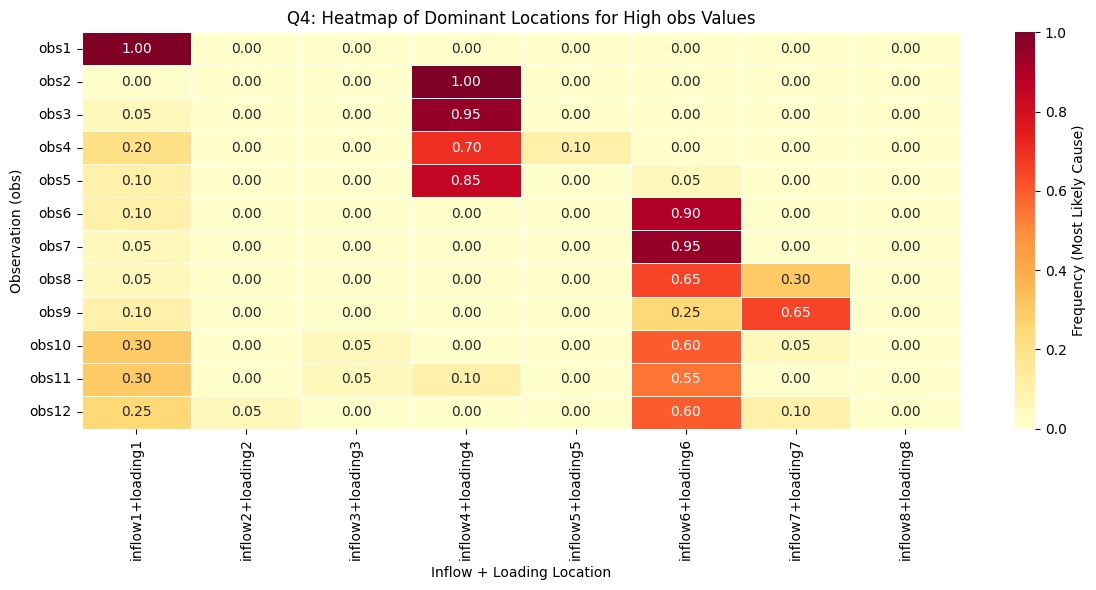

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_df,
    cmap="YlOrRd",        # 黄→橙→红，适合表示“强度/频率”
    annot=True,           # 在格子里显示数值
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Frequency (Most Likely Cause)"}
)

plt.xlabel("Inflow + Loading Location")
plt.ylabel("Observation (obs)")
plt.title("Q4: Heatmap of Dominant Locations for High obs Values")

plt.tight_layout()
plt.show()
